# Late deliveries: analysis

This notebook shows how common late orders are, the model comparison, how the threshold was chosen from costs, and the single test-set result.

It **does not re-score the test set**. The test set was scored once by `python -m latedeliveries.train`, and this notebook reads the saved `reports/` and `models/` files. The leakage experiment at the end uses the training data only.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate

from latedeliveries.data import make_orders
from latedeliveries.pipeline import (
    CATEGORICAL_FEATURES,
    NUMERIC_FEATURES,
    RANDOM_STATE,
    build_pipeline,
    split_data,
)
from latedeliveries.train import CV

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
REPORTS = ROOT / "reports"
MODELS = ROOT / "models"

INK, MUTED, BLUE = "#0b0b0b", "#52514e", "#2a78d6"
plt.rcParams.update(
    {
        "figure.facecolor": "#fcfcfb",
        "axes.facecolor": "#fcfcfb",
        "axes.edgecolor": MUTED,
        "axes.labelcolor": INK,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

## 1. How common are late orders?

In [2]:
orders = make_orders()
print(f"{len(orders)} orders, late rate {orders['late'].mean():.1%}")
print("\nMissing values per column:")
print(orders.isna().sum()[orders.isna().sum() > 0])
orders.head()

3000 orders, late rate 15.6%

Missing values per column:
prep_minutes        189
customer_rating    1489
dtype: int64


,order_id,distance_km,items,hour,weather,day_type,vehicle,prep_minutes,courier_months,customer_rating,late
0,100000,3.4,2,13,rain,weekend,bike,13.6,48,4.0,0
1,100001,2.7,2,12,rain,weekday,scooter,11.7,2,4.0,0
2,100002,2.4,4,13,clear,weekend,scooter,22.4,53,3.0,1
3,100003,3.5,1,17,clear,weekend,bike,12.5,39,NaN,0
4,100004,2.3,5,11,clear,weekend,car,5.9,9,5.0,0


In [3]:
X_train, X_test, y_train, y_test = split_data()
print(f"train: {len(X_train)} rows, late rate {y_train.mean():.2%}")
print(f"test:  {len(X_test)} rows, late rate {y_test.mean():.2%}")

train: 2250 rows, late rate 15.60%
test:  750 rows, late rate 15.60%


About one order in six is late. A model that always says *on time* is already about 84% accurate, which is why accuracy alone is not used to choose a model.

## 2. Columns used and left out

In [4]:
print("Numeric:    ", NUMERIC_FEATURES)
print("Categorical:", CATEGORICAL_FEATURES)
print()
excluded = {
    "order_id": "an arbitrary label; any pattern in it is coincidence",
    "prep_minutes": "actual kitchen time, only known after cooking",
    "customer_rating": "given after delivery and driven by lateness (leak)",
    "late": "the target",
}
for column, reason in excluded.items():
    print(f"left out {column:16s} {reason}")

Numeric:     ['distance_km', 'items', 'hour', 'courier_months']
Categorical: ['weather', 'day_type', 'vehicle']

left out order_id         an arbitrary label; any pattern in it is coincidence
left out prep_minutes     actual kitchen time, only known after cooking
left out customer_rating  given after delivery and driven by lateness (leak)
left out late             the target


## 3. Model comparison

Five-fold stratified cross-validation on the training data only. `lowest_cost` is the cheapest total cost each model reaches on its out-of-fold probabilities across the threshold grid.

In [5]:
cv_results = pd.read_csv(REPORTS / "cv_results.csv")
cv_results.round(3)

,model,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std,best_threshold,lowest_cost
0,Dummy,0.844,0.001,0.000,0.000,0.000,0.000,0.000,0.000,0.500,0.000,0.2,5265
1,Logistic Regression,0.862,0.013,0.669,0.114,0.222,0.066,0.330,0.086,0.779,0.038,0.3,4205
2,Balanced Logistic Regression,0.731,0.026,0.323,0.035,0.655,0.054,0.432,0.040,0.779,0.038,0.7,4183
3,Random Forest,0.853,0.009,0.568,0.069,0.216,0.066,0.310,0.078,0.736,0.030,0.3,4494


Both logistic regressions reach the lowest cost (about \$4,190 vs \$4,494 for the random forest and \$5,265 for the baseline) and share the best ROC-AUC. They are within about 1% of each other on cost, so the logistic family is chosen and `class_weight` is left to the grid search.

## 4. Tuning

In [6]:
info = json.loads((MODELS / "model_info.json").read_text())
print("Best settings:", info["best_settings"])
print(json.dumps(info["tuning"], indent=2))

Best settings: {'model__C': 0.1, 'model__class_weight': None}
{
  "scoring": "roc_auc",
  "untuned_cv_roc_auc_mean": 0.7794982286441885,
  "untuned_cv_roc_auc_std": 0.038411806364394424,
  "tuned_cv_roc_auc_mean": 0.7797518819345737,
  "tuned_cv_roc_auc_std": 0.037638458841439806,
  "gain": 0.0002536532903851807,
  "gain_exceeds_fold_spread": false
}


Tuning moved ROC-AUC by about 0.0003, far smaller than the fold-to-fold spread of about 0.038. **Tuning did not meaningfully beat the untuned model.**

## 5. Cost against threshold

Out-of-fold training probabilities, \$4 per flagged order plus \$15 per late order that is not flagged.

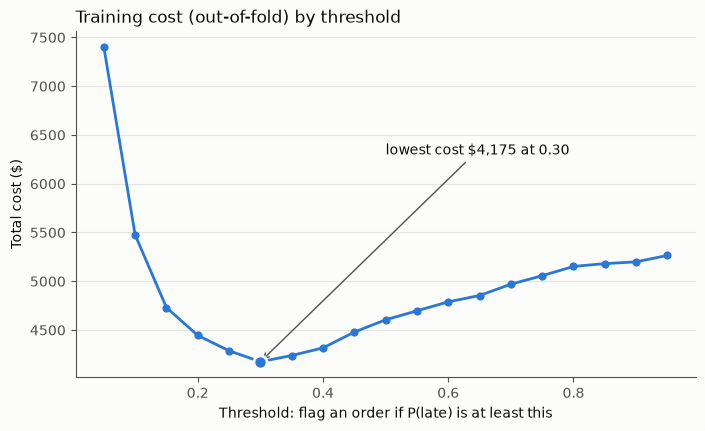

In [7]:
costs = pd.read_csv(REPORTS / "threshold_costs.csv")
best = costs.loc[costs["cost"].idxmin()]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(costs["threshold"], costs["cost"], color=BLUE, linewidth=2)
ax.scatter(costs["threshold"], costs["cost"], color=BLUE, s=24, zorder=3)
ax.scatter(
    [best["threshold"]],
    [best["cost"]],
    s=90,
    color=BLUE,
    edgecolor="#fcfcfb",
    linewidth=2,
    zorder=4,
)
ax.annotate(
    f"lowest cost ${best['cost']:,.0f} at {best['threshold']:.2f}",
    (best["threshold"], best["cost"]),
    xytext=(0.5, 6300),
    color=INK,
    arrowprops={"arrowstyle": "->", "color": MUTED, "linewidth": 1},
)
ax.set_title("Training cost (out-of-fold) by threshold", loc="left", color=INK)
ax.set_xlabel("Threshold: flag an order if P(late) is at least this")
ax.set_ylabel("Total cost ($)")
ax.yaxis.grid(True, color="#e6e5e0", linewidth=0.8)
ax.set_axisbelow(True)
plt.show()

The lowest cost is at 0.30, close to the break-even probability 4 / 15 ≈ 0.27, where a voucher costs the same as the expected loss of not sending it. The default 0.5 would cost about \$430 more on the same training predictions.

## 6. Test-set result (scored once by `train.py`)

### Confusion matrix

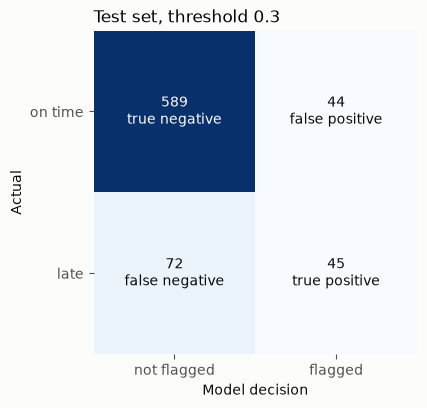

accuracy     0.845
precision    0.506
recall       0.385
f1           0.437
roc_auc      0.781
dtype: float64

In [8]:
metrics = json.loads((REPORTS / "metrics.json").read_text())
matrix = np.array(metrics["confusion_matrix"])

fig, ax = plt.subplots(figsize=(4.8, 4.2))
ax.imshow(matrix, cmap="Blues")
labels = [["true negative", "false positive"], ["false negative", "true positive"]]
for i in range(2):
    for j in range(2):
        dark = matrix[i, j] > matrix.max() / 2
        ax.text(
            j,
            i,
            f"{matrix[i, j]}\n{labels[i][j]}",
            ha="center",
            va="center",
            color="white" if dark else INK,
        )
ax.set_xticks([0, 1], ["not flagged", "flagged"])
ax.set_yticks([0, 1], ["on time", "late"])
ax.set_xlabel("Model decision")
ax.set_ylabel("Actual")
ax.set_title(f"Test set, threshold {metrics['threshold']}", loc="left")
for spine in ax.spines.values():
    spine.set_visible(False)
plt.show()

pd.Series(
    {k: metrics[k] for k in ["accuracy", "precision", "recall", "f1", "roc_auc"]}
).round(3)

### Cost of the three policies on the test set (750 orders)

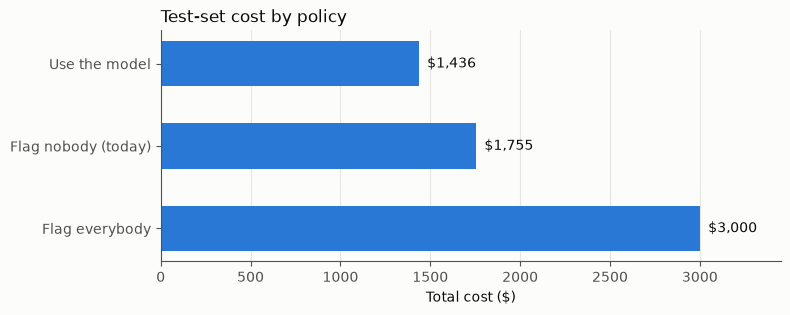

Model saves $319 (18.2%) against flagging nobody


In [9]:
policies = pd.Series(
    {
        "Flag everybody": metrics["cost_flag_everybody"],
        "Flag nobody (today)": metrics["cost_flag_nobody"],
        "Use the model": metrics["cost_model"],
    }
)

fig, ax = plt.subplots(figsize=(8, 3))
bars = ax.barh(policies.index, policies.values, color=BLUE, height=0.55)
ax.bar_label(bars, labels=[f"${v:,}" for v in policies.values], padding=6, color=INK)
ax.set_xlabel("Total cost ($)")
ax.set_xlim(0, policies.max() * 1.15)
ax.set_title("Test-set cost by policy", loc="left", color=INK)
ax.xaxis.grid(True, color="#e6e5e0", linewidth=0.8)
ax.set_axisbelow(True)
plt.show()

saving = metrics["cost_flag_nobody"] - metrics["cost_model"]
print(
    f"Model saves ${saving:,} ({saving / metrics['cost_flag_nobody']:.1%})"
    " against flagging nobody"
)

## 7. Leakage check (training data only)

The comparison is run again with each excluded column added back, then they are taken out again. The final model never uses them.

In [10]:
full_train = make_orders().loc[X_train.index]


def cv_auc(extra_numeric):
    pipeline = build_pipeline(
        LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
        NUMERIC_FEATURES + extra_numeric,
        CATEGORICAL_FEATURES,
    )
    scores = cross_validate(pipeline, full_train, y_train, cv=CV, scoring="roc_auc")[
        "test_score"
    ]
    return scores.mean(), scores.std()


rows = []
for name, extra in [
    ("approved features", []),
    ("+ prep_minutes", ["prep_minutes"]),
    ("+ customer_rating", ["customer_rating"]),
]:
    mean, std = cv_auc(extra)
    rows.append({"features": name, "roc_auc_mean": mean, "roc_auc_std": std})
leakage = pd.DataFrame(rows)
leakage["change"] = leakage["roc_auc_mean"] - leakage["roc_auc_mean"].iloc[0]
leakage.round(3)

,features,roc_auc_mean,roc_auc_std,change
0,approved features,0.779,0.038,0.000
1,+ prep_minutes,0.795,0.034,0.016
2,+ customer_rating,0.905,0.021,0.125


`customer_rating` makes the score jump sharply because the rating is given *after* the delivery and is driven by lateness. That is a warning, not good news: the column would not exist when the prediction is made. `prep_minutes` helps a little because the true prep time affects lateness, but its value is only known after the kitchen has finished, so it is also left out.

## Recommendation

**Would I use this model?** Yes. On 750 orders it has never seen, it cut the cost from \$1,755 (flag nobody, today's policy) to \$1,436, a saving of about 18%, and flagging everybody (\$3,000) is far worse.

**Why this threshold?** 0.30 gave the lowest total cost on out-of-fold training predictions. It sits near the break-even probability of 4/15 ≈ 0.27, where a \$4 voucher equals the expected \$15 loss. The test set played no part in choosing it.

**What did I exclude and why?** `customer_rating` is given after delivery and is driven by lateness, so it leaks the answer. `prep_minutes` is only known once cooking ends. `order_id` is an arbitrary label.

**One limitation.** The model catches only 38% of late orders (ROC-AUC 0.78), and the saving comes from one test set of 117 late orders. A different sample could move it by a few hundred dollars. The data is also invented, so the costs should be checked against real orders before rollout.